In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn
import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [2]:
# 100,000 features (DPD)
df1 = pd.read_csv('diabetes_dataset_with_notes.csv')


In [3]:
df1.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0,"Overweight, advised dietary and exercise modif..."
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0,Healthy BMI range.
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0,"Young patient, generally lower risk but needs ..."
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0,"Overweight, advised dietary and exercise modif..."
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0,"Healthy BMI range. High HbA1c level, indicativ..."


In [4]:
df1 = df1.drop(columns=['clinical_notes', 'location'])
df1 = df1.drop(columns=['year', 'race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other'  ])

In [5]:
pd.DataFrame({
    "DType": df1.dtypes,
    "null_ratio": df1.isnull().sum(),
    "nunique": df1.nunique()
})

,DType,null_ratio,nunique
gender,object,0,3
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,object,0,6
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [6]:
df1.gender.value_counts()

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

In [7]:
df1['gender'] = df1['gender'].replace("Other", np.nan)
df1['gender'] = df1['gender'].fillna(df1['gender'].mode()[0])

In [8]:
df1.gender.value_counts()

gender
Female    58570
Male      41430
Name: count, dtype: int64

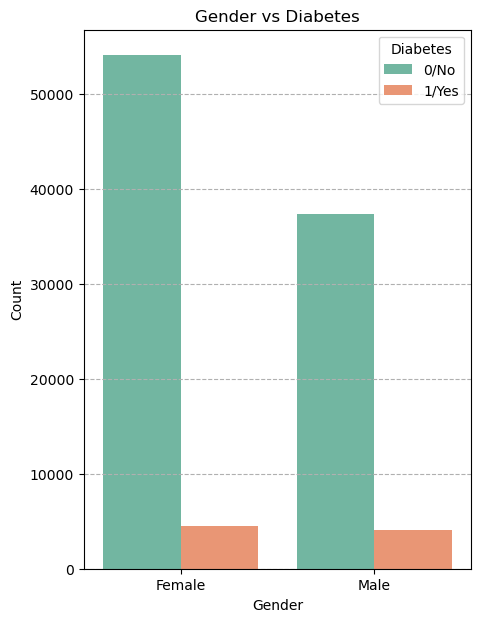

In [9]:
plt.figure(figsize=(5,7))
sns.countplot(x='gender', hue='diabetes', data=df1, palette='Set2')
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [10]:
# Encoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df1['gender'] = le.fit_transform(df1['gender'])

In [11]:
df1.gender.value_counts()

gender
0    58570
1    41430
Name: count, dtype: int64

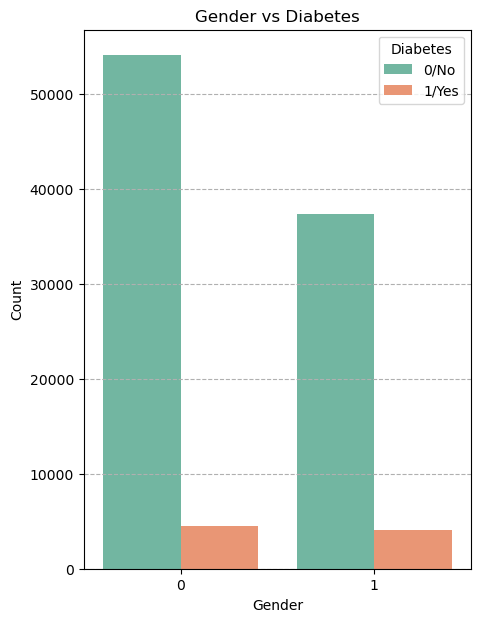

In [12]:
plt.figure(figsize=(5,7))
sns.countplot(x='gender', hue='diabetes', data=df1, palette='Set2')
plt.title("Gender vs Diabetes")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [13]:
pd.DataFrame({
    "DType": df1.dtypes,
    "null_ratio": df1.isnull().sum(),
    "nunique": df1.nunique()
})

,DType,null_ratio,nunique
gender,int64,0,2
age,float64,0,102
hypertension,int64,0,2
heart_disease,int64,0,2
smoking_history,object,0,6
bmi,float64,0,4247
hbA1c_level,float64,0,18
blood_glucose_level,int64,0,18
diabetes,int64,0,2


In [14]:
df1.smoking_history.value_counts()

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

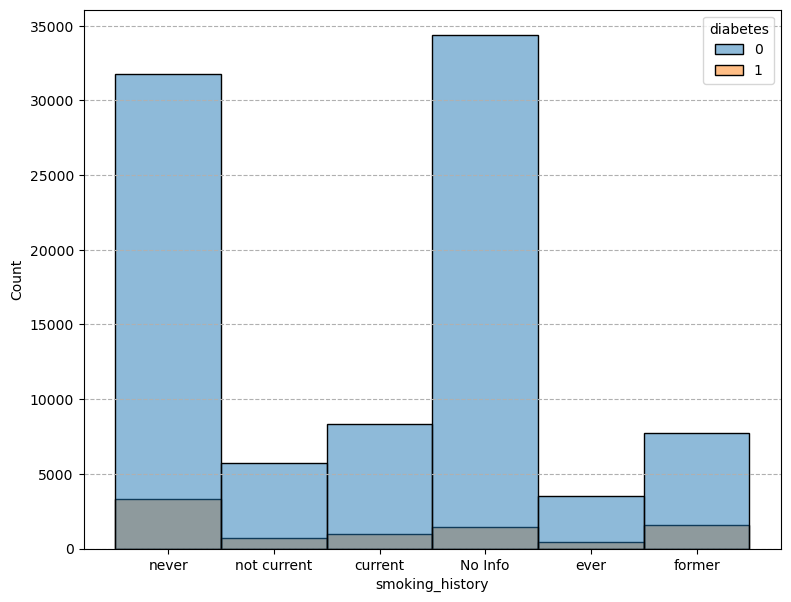

In [15]:
plt.figure(figsize=(9,7))
sns.histplot(x='smoking_history', hue='diabetes', data=df1)

plt.grid(axis='y',linestyle='--')
plt.show()

In [16]:
# Step 1: Standardize text 
df1['smoking_history'] = df1['smoking_history'].str.lower().str.strip()

# Step 2: Replace inconsistent values
df1['smoking_history'] = df1['smoking_history'].replace({
    'No Info': 'unknown',
    'not current': 'former',
    'ever': 'former'
})

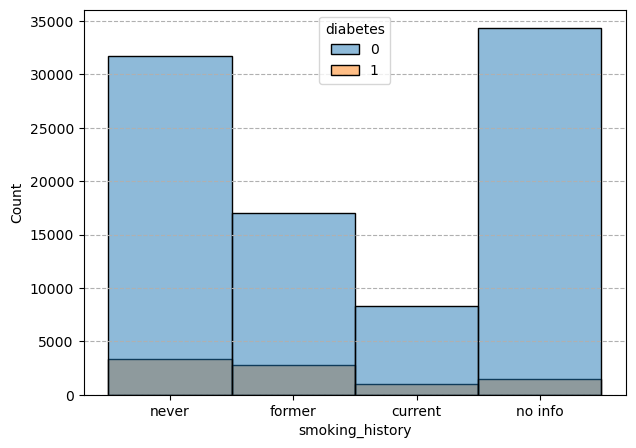

In [17]:
plt.figure(figsize=(7,5))
sns.histplot(x='smoking_history', hue='diabetes', data=df1)

plt.grid(axis='y',linestyle='--')
plt.show()

In [18]:
df1['smoking_history'].value_counts()

smoking_history
no info    35816
never      35095
former     19803
current     9286
Name: count, dtype: int64

In [19]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df1['smoking_history'] = le.fit_transform(df1['smoking_history'])

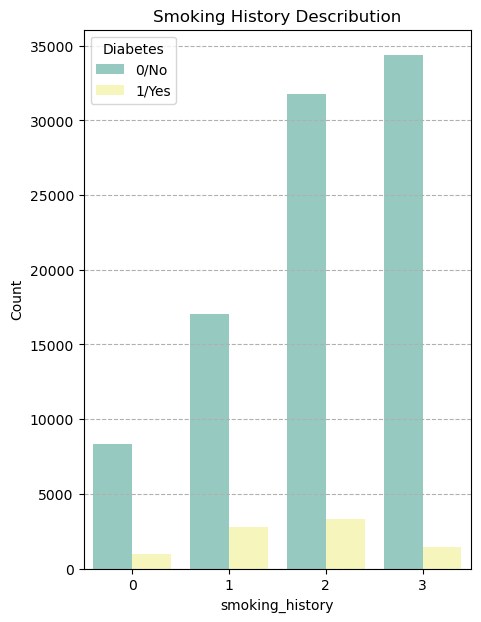

In [20]:
plt.figure(figsize=(5,7))
sns.countplot(x='smoking_history', hue='diabetes', data=df1, palette='Set3')
plt.title("Smoking History Describution")
plt.xlabel("smoking_history")
plt.ylabel("Count")
plt.legend(title="Diabetes", labels=["0/No", "1/Yes"])
plt.grid(axis='y',linestyle='--')
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

X = df1.drop(columns=['diabetes'])
y = df1['diabetes']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Optional: Check distribution
print("Train distribution:\n", y_train.value_counts(normalize=True))
print("\nValidation distribution:\n", y_val.value_counts(normalize=True))
print("\nTest distribution:\n", y_test.value_counts(normalize=True))

Train distribution:
 diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

Validation distribution:
 diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

Test distribution:
 diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


In [22]:
numerical_cols = ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']

# Function to count outliers using IQR (without modifying data)
def check_outliers(df1, columns):
    results = {}

    for col in columns:
        Q1 = df1[col].quantile(0.25)
        Q3 = df1[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = ((df1[col] < lower) | (df1[col] > upper)).sum()
        results[col] = outliers

    return results

# Count outliers BEFORE IQR
before_outliers = check_outliers(X_train, numerical_cols)

print("Outliers BEFORE IQR:")
for col, count in before_outliers.items():
    print(f"{col}: {count}")

Outliers BEFORE IQR:
age: 0
bmi: 4936
hbA1c_level: 907
blood_glucose_level: 1421


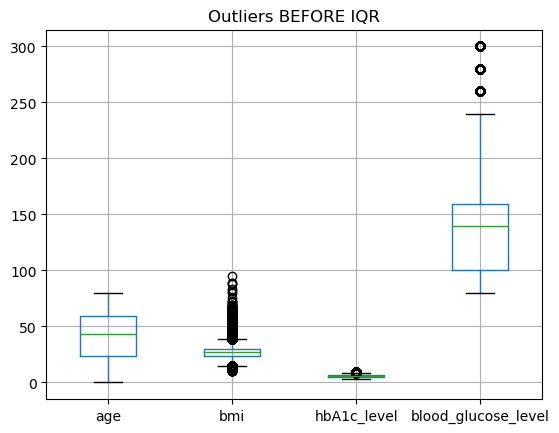

In [23]:
# Visualize (boxplot)
X_train[numerical_cols].boxplot()
plt.title("Outliers BEFORE IQR")
plt.show()

In [24]:
# Step 1: Calculate IQR bounds using TRAINING data
bounds = {}

for col in numerical_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    bounds[col] = (lower_bound, upper_bound)

# Step 2: Function to cap outliers
def cap_outliers(df1, bounds):
    df1 = df1.copy()
    for col in bounds:
        lower, upper = bounds[col]
        df1[col] = np.clip(df1[col], lower, upper)
    return df1

# Step 3: Apply to all datasets
X_train = cap_outliers(X_train, bounds)
X_val   = cap_outliers(X_val, bounds)
X_test  = cap_outliers(X_test, bounds)

In [25]:
# Count outliers AFTER IQR
after_outliers = check_outliers(X_train, numerical_cols)

print("Outliers After IQR:")
for col, count in after_outliers.items():
    print(f"{col}: {count}")

Outliers After IQR:
age: 0
bmi: 0
hbA1c_level: 0
blood_glucose_level: 0


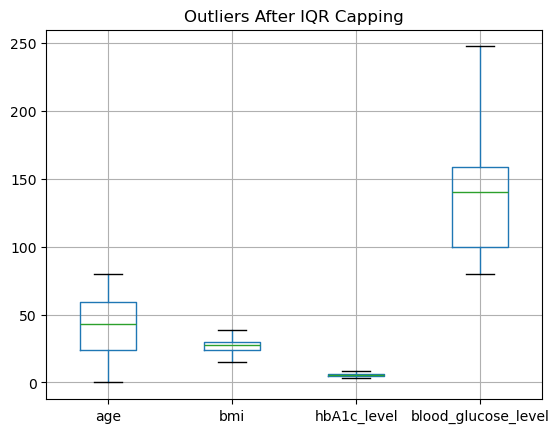

In [26]:
X_train[numerical_cols].boxplot()
plt.title("Outliers After IQR Capping")
plt.show()

In [27]:
from sklearn.preprocessing import MinMaxScaler

# Step 1: Initialize scaler
scaler = MinMaxScaler()

# Step 2: Fit on TRAINING data (after SMOTE)
X_train = scaler.fit_transform(X_train)

# Step 3: Transform validation and test data
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [28]:
# Check min and max values
print("TRAIN MIN:", X_train.min())
print("TRAIN MAX:", X_train.max())

print("\nVALIDATION MIN:", X_val.min())
print("VALIDATION MAX:", X_val.max())

print("\nTEST MIN:", X_test.min())
print("TEST MAX:", X_test.max())

TRAIN MIN: 0.0
TRAIN MAX: 1.0

VALIDATION MIN: 0.0
VALIDATION MAX: 1.0

TEST MIN: 0.0
TEST MAX: 1.0


In [29]:
pip install smote-variants

Note: you may need to restart the kernel to use updated packages.


In [30]:
!pip install torch

In [31]:
!pip install pytorch-tabular

In [32]:
pip install pytorch-tabnet

Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install torch torchvision torchaudio

Note: you may need to restart the kernel to use updated packages.


In [34]:
!pip install xgboost catboost

In [35]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# ProWSyn will be applied inside each training fold during cross-validation.
X_train_meta = X_train
y_train_meta = y_train
X_test_meta = X_test
y_test_meta = y_test

print(f"Training data shape: {X_train_meta.shape}")
print(f"Training labels shape: {y_train_meta.shape}")
print(f"Test data shape: {X_test_meta.shape}")
print(f"Test labels shape: {y_test_meta.shape}")

Training data shape: (70000, 8)
Training labels shape: (70000,)
Test data shape: (15000, 8)
Test labels shape: (15000,)


In [36]:
# CELL: DNN Training with Cross-Validation
import smote_variants as sv
from collections import Counter
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.metrics import Recall

N_FOLDS = 5

# Initialize OOF and test prediction arrays
oof_dnn = np.zeros(len(X_train_meta))
test_dnn = np.zeros(len(X_test_meta))

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"DNN FOLD {fold}/{N_FOLDS}")
    print("=" * 60)
    
    # Split data
    X_fold_train = X_train_meta[train_idx]          # NumPy array
    y_fold_train = y_train_meta.iloc[train_idx]     # Pandas Series → positional indexing

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx]

    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=42
    )

    X_fold_train, y_fold_train = oversampler.sample(
    np.asarray(X_fold_train),
    np.asarray(y_fold_train)
    )
    
    print(f"Fold train: {X_fold_train.shape}")
    print(f"Fold validation: {X_fold_val.shape}")
    print(f"Training class distribution after ProWSyn: {Counter(y_fold_train)}")
    
    # Build DNN model
    model_dnn = Sequential([
        Input(shape=(X_fold_train.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(64, activation='tanh'),
        Dropout(0.3),
        Dense(32, activation='tanh'),
        Dropout(0.25),
        Dense(16, activation='tanh'),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(4, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model_dnn.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', Recall()]
    )
    
    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
    
    # Train
    history_dnn = model_dnn.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=40,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )
    
    # OOF prediction
    oof_dnn[val_idx] = model_dnn.predict(X_fold_val, verbose=0).ravel()
    
    # Test prediction (accumulate)
    test_dnn += model_dnn.predict(X_test_meta, verbose=0).ravel() / N_FOLDS

print("\nDNN OOF and test predictions completed!")

2026-09-29 14:54:38,639:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 14:54:38,641:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:54:38,647:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 1/5


2026-09-29 14:54:39,113:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:54:39,115:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 14:54:39,483:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:54:39,484:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 14:54:39,736:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:54:39,737:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 14:54:39,874:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:54:39,875:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 14:54:39,957:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 14:56:59,092:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 14:57:01,157:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 14:57:01,795:INFO:ProWSyn: simplex sampli

Fold train: (102480, 8)
Fold validation: (14000, 8)
Training class distribution after ProWSyn: Counter({np.int64(0): 51240, np.int64(1): 51240})
Epoch 1/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8932 - loss: 0.2513 - recall: 0.9073 - val_accuracy: 0.9438 - val_loss: 0.1395 - val_recall: 0.7353
Epoch 2/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9137 - loss: 0.1960 - recall: 0.9221 - val_accuracy: 0.9229 - val_loss: 0.1641 - val_recall: 0.8361
Epoch 3/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9195 - loss: 0.1782 - recall: 0.9267 - val_accuracy: 0.9163 - val_loss: 0.1595 - val_recall: 0.8504
Epoch 4/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9224 - loss: 0.1673 - recall: 0.9214 - val_accuracy: 0.9152 - val_loss: 0.1777 - val_recall: 0.8714
Epoch 5/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9232 - loss: 0.1614 - recall: 0.9206 - val_accuracy: 0.9519 - val_loss: 0.1151 - val_recall: 0.7756
Epoch 6/40
1602

2026-09-29 14:57:23,338:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 14:57:23,342:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 14:57:23,353:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


...

Fold train: (102480, 8)
Fold validation: (14000, 8)
Training class distribution after ProWSyn: Counter({np.int64(0): 51240, np.int64(1): 51240})
Epoch 1/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8866 - loss: 0.3679 - recall_3: 0.8887 - val_accuracy: 0.9221 - val_loss: 0.3436 - val_recall_3: 0.7908
Epoch 2/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9150 - loss: 0.2415 - recall_3: 0.9007 - val_accuracy: 0.9163 - val_loss: 0.2450 - val_recall_3: 0.8084
Epoch 3/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9207 - loss: 0.1983 - recall_3: 0.9097 - val_accuracy: 0.9357 - val_loss: 0.1846 - val_recall_3: 0.7941
Epoch 4/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9224 - loss: 0.1793 - recall_3: 0.9124 - val_accuracy: 0.9315 - val_loss: 0.1713 - val_recall_3: 0.7983
Epoch 5/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9251 - loss: 0.1675 - recall_3: 0.9147 - val_accuracy: 0.9344 - val_loss: 0.1655 - val_recall_3: 0.

2026-09-29 15:05:41,515:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:05:41,518:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:05:41,526:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



DNN FOLD 5/5


2026-09-29 15:05:41,979:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:05:41,981:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:05:42,349:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:05:42,351:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:05:42,599:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:05:42,601:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:05:42,735:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:05:42,736:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:05:42,803:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:08:05,916:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:08:07,977:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:08:08,711:INFO:ProWSyn: simplex sampli

Fold train: (102480, 8)
Fold validation: (14000, 8)
Training class distribution after ProWSyn: Counter({np.int64(0): 51240, np.int64(1): 51240})
Epoch 1/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8855 - loss: 0.3678 - recall_4: 0.8810 - val_accuracy: 0.9346 - val_loss: 0.3116 - val_recall_4: 0.7849
Epoch 2/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9147 - loss: 0.2390 - recall_4: 0.9026 - val_accuracy: 0.9309 - val_loss: 0.2248 - val_recall_4: 0.8134
Epoch 3/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9195 - loss: 0.1996 - recall_4: 0.9103 - val_accuracy: 0.9078 - val_loss: 0.2081 - val_recall_4: 0.8672
Epoch 4/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9218 - loss: 0.1821 - recall_4: 0.9154 - val_accuracy: 0.9199 - val_loss: 0.1864 - val_recall_4: 0.8496
Epoch 5/40
1602/1602 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9231 - loss: 0.1714 - recall_4: 0.9144 - val_accuracy: 0.9170 - val_loss: 0.1785 - val_recall_4: 0.

In [37]:
from sklearn.metrics import (classification_report, confusion_matrix, 
accuracy_score, roc_auc_score, average_precision_score)

dnn_prob = model_dnn.predict(X_test).ravel()
dnn_pred = (dnn_prob > 0.5).astype(int)

print("DNN Results, Classification Report")
print(classification_report(y_test, dnn_pred))

print("ROC-AUC:", roc_auc_score(y_test, dnn_prob))
print("PR-AUC:", average_precision_score(y_test, dnn_prob))

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step
DNN Results, Classification Report
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.64      0.77      0.70      1275

    accuracy                           0.94     15000
   macro avg       0.81      0.87      0.84     15000
weighted avg       0.95      0.94      0.95     15000

ROC-AUC: 0.9689549483910138
PR-AUC: 0.8483732674836288


In [38]:
# CELL: TabNet Training with Cross-Validation

from pytorch_tabnet.tab_model import TabNetClassifier
import torch

# Initialize OOF and test prediction arrays
oof_tabnet = np.zeros(len(X_train_meta))
test_tabnet = np.zeros(len(X_test_meta))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"TABNET FOLD {fold}/{N_FOLDS}")
    print("=" * 60)
    
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()  

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()    


    # Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=42
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )                                                  

    print("Training class distribution:", Counter(y_fold_train))

    
    tabnet_model = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=7,
        gamma=1.5,
        lambda_sparse=1e-2,
        optimizer_fn=torch.optim.AdamW,
        optimizer_params=dict(lr=0.005),
        seed=42 + fold,
        verbose=1
    )
    
    tabnet_model.fit(
        X_fold_train,
        y_fold_train,
        eval_set=[(X_fold_val, y_fold_val)],
        eval_name=['val'],
        eval_metric=['auc'],
        max_epochs=50,
        patience=5,
        batch_size=1024,
        virtual_batch_size=128
    )
    
    # OOF prediction
    oof_tabnet[val_idx] = tabnet_model.predict_proba(X_fold_val)[:, 1]
    
    # Test prediction
    test_tabnet += tabnet_model.predict_proba(X_test_meta)[:, 1] / N_FOLDS

print("\nTabNet OOF and test predictions completed!")

2026-09-29 15:08:39,349:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:08:39,351:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:08:39,357:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



TABNET FOLD 1/5


2026-09-29 15:08:39,814:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:08:39,817:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:08:40,197:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:08:40,198:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:08:40,442:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:08:40,443:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:08:40,580:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:08:40,581:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:08:40,663:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:10:57,764:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:10:59,574:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:10:59,993:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.34368 | val_auc: 0.92599 |  0:00:04s
epoch 1  | loss: 0.2228  | val_auc: 0.94491 |  0:00:08s
epoch 2  | loss: 0.20409 | val_auc: 0.96473 |  0:00:13s
epoch 3  | loss: 0.19097 | val_auc: 0.96627 |  0:00:17s
epoch 4  | loss: 0.1764  | val_auc: 0.96699 |  0:00:22s
epoch 5  | loss: 0.17426 | val_auc: 0.96923 |  0:00:26s
epoch 6  | loss: 0.16385 | val_auc: 0.96661 |  0:00:30s
epoch 7  | loss: 0.15991 | val_auc: 0.97244 |  0:00:35s
epoch 8  | loss: 0.15157 | val_auc: 0.97056 |  0:00:39s
epoch 9  | loss: 0.15243 | val_auc: 0.97221 |  0:00:43s
epoch 10 | loss: 0.15013 | val_auc: 0.97093 |  0:00:48s
epoch 11 | loss: 0.14771 | val_auc: 0.97069 |  0:00:52s
epoch 12 | loss: 0.14721 | val_auc: 0.97168 |  0:00:57s

Early stopping occurred at epoch 12 with best_epoch = 7 and best_val_auc = 0.97244


2026-09-29 15:12:01,909:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:12:01,911:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:12:01,920:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski


...

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.52318 | val_auc: 0.9231  |  0:00:04s
epoch 1  | loss: 0.2233  | val_auc: 0.93652 |  0:00:09s
epoch 2  | loss: 0.20403 | val_auc: 0.96118 |  0:00:13s
epoch 3  | loss: 0.19015 | val_auc: 0.96498 |  0:00:17s
epoch 4  | loss: 0.17815 | val_auc: 0.96787 |  0:00:22s
epoch 5  | loss: 0.17111 | val_auc: 0.96558 |  0:00:26s
epoch 6  | loss: 0.18013 | val_auc: 0.96685 |  0:00:30s
epoch 7  | loss: 0.17694 | val_auc: 0.96748 |  0:00:35s
epoch 8  | loss: 0.16442 | val_auc: 0.96803 |  0:00:39s
epoch 9  | loss: 0.16096 | val_auc: 0.96713 |  0:00:43s
epoch 10 | loss: 0.16009 | val_auc: 0.96904 |  0:00:48s
epoch 11 | loss: 0.15717 | val_auc: 0.96741 |  0:00:52s
epoch 12 | loss: 0.16044 | val_auc: 0.96977 |  0:00:56s
epoch 13 | loss: 0.15401 | val_auc: 0.96885 |  0:01:01s
epoch 14 | loss: 0.14597 | val_auc: 0.9724  |  0:01:05s
epoch 15 | loss: 0.14031 | val_auc: 0.96991 |  0:01:09s
epoch 16 | loss: 0.13594 

2026-09-29 15:23:26,775:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:23:26,777:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:23:26,787:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



TABNET FOLD 5/5


2026-09-29 15:23:27,264:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:23:27,267:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:23:27,635:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:23:27,637:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:23:27,889:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:23:27,890:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:23:28,027:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:23:28,028:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:23:28,099:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:25:45,722:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:25:47,797:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:25:48,275:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
epoch 0  | loss: 0.38344 | val_auc: 0.89315 |  0:00:04s
epoch 1  | loss: 0.23194 | val_auc: 0.94913 |  0:00:08s
epoch 2  | loss: 0.21126 | val_auc: 0.9566  |  0:00:13s
epoch 3  | loss: 0.20512 | val_auc: 0.95852 |  0:00:17s
epoch 4  | loss: 0.20019 | val_auc: 0.96632 |  0:00:21s
epoch 5  | loss: 0.18973 | val_auc: 0.96914 |  0:00:26s
epoch 6  | loss: 0.17973 | val_auc: 0.96731 |  0:00:30s
epoch 7  | loss: 0.17427 | val_auc: 0.96715 |  0:00:34s
epoch 8  | loss: 0.16937 | val_auc: 0.96928 |  0:00:39s
epoch 9  | loss: 0.1657  | val_auc: 0.97073 |  0:00:43s
epoch 10 | loss: 0.15823 | val_auc: 0.9694  |  0:00:47s
epoch 11 | loss: 0.15646 | val_auc: 0.96733 |  0:00:52s
epoch 12 | loss: 0.15329 | val_auc: 0.97273 |  0:00:56s
epoch 13 | loss: 0.14934 | val_auc: 0.97128 |  0:01:00s
epoch 14 | loss: 0.14602 | val_auc: 0.97239 |  0:01:05s
epoch 15 | loss: 0.14574 | val_auc: 0.96944 |  0:01:09s
epoch 16 | loss: 0.14457 

In [39]:
tabnet_prob = tabnet_model.predict_proba(X_test)[:, 1]
tabnet_pred = (tabnet_prob > 0.5).astype(int)

print("Tabnet Results, Classification Report:\n")
print(classification_report(y_test, tabnet_pred))
print("ROC-AUC:", roc_auc_score(y_test, tabnet_prob))
print("PR-AUC:", average_precision_score(y_test, tabnet_prob))

Tabnet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96     13725
           1       0.58      0.81      0.68      1275

    accuracy                           0.93     15000
   macro avg       0.78      0.88      0.82     15000
weighted avg       0.95      0.93      0.94     15000

ROC-AUC: 0.9698688667452409
PR-AUC: 0.8457056027958185


In [40]:
# CELL: Simple DNN (ResNet-style) Training with Cross-Validation

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Initialize OOF and test prediction arrays
oof_resnet = np.zeros(len(X_train_meta))
test_resnet = np.zeros(len(X_test_meta))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_meta, y_train_meta), 1):
    print("\n" + "=" * 60)
    print(f"SIMPLE DNN FOLD {fold}/{N_FOLDS}")
    print("=" * 60)
    
    X_fold_train = X_train_meta[train_idx]
    y_fold_train = y_train_meta.iloc[train_idx].copy()

    X_fold_val = X_train_meta[val_idx]
    y_fold_val = y_train_meta.iloc[val_idx].copy()
    
    # Build model
    resnet_model = Sequential([
        Input(shape=(X_fold_train.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    # FIX 2: Apply ProWSyn ONLY to the training fold
    oversampler = sv.ProWSyn(
        n_neighbors=3,
        random_state=42
    )

    X_fold_train, y_fold_train = oversampler.sample(
        np.asarray(X_fold_train),
        np.asarray(y_fold_train)
    )

    print("Training class distribution:", Counter(y_fold_train))
    print(f"Validation shape: {X_fold_val.shape}")


    
    resnet_model.compile(
        optimizer=AdamW(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    early_stop = EarlyStopping(
        monitor='val_loss',
        mode='min',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    
    history = resnet_model.fit(
        X_fold_train,
        y_fold_train,
        validation_data=(X_fold_val, y_fold_val),
        epochs=100,
        batch_size=1024,
        callbacks=[early_stop],
        verbose=1
    )
    
    # OOF prediction
    oof_resnet[val_idx] = resnet_model.predict(X_fold_val, verbose=0).ravel()
    
    # Test prediction
    test_resnet += resnet_model.predict(X_test_meta, verbose=0).ravel() / N_FOLDS

print("\nSimple DNN OOF and test predictions completed!")


SIMPLE DNN FOLD 1/5


2026-09-29 15:27:10,362:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:27:10,365:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:27:10,374:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:27:10,847:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:27:10,850:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:27:11,218:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:27:11,219:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:27:11,464:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:27:

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
Validation shape: (14000, 8)
Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8070 - loss: 0.4089 - val_accuracy: 0.8687 - val_loss: 0.2892
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9016 - loss: 0.2338 - val_accuracy: 0.9158 - val_loss: 0.1960
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9084 - loss: 0.2166 - val_accuracy: 0.9275 - val_loss: 0.1737
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9129 - loss: 0.2049 - val_accuracy: 0.9241 - val_loss: 0.1792
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9142 - loss: 0.1981 - val_accuracy: 0.9185 - val_loss: 0.1918
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9169 - loss: 0.1912 - val_accuracy: 0.9348 - val_loss: 0.1609
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9170 - loss: 0.1874 - val_accuracy: 0.9315 - val_lo

2026-09-29 15:29:49,590:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:29:49,593:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:29:49,604:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



SIMPLE DNN FOLD 2/5


...

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
Validation shape: (14000, 8)
Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7976 - loss: 0.4197 - val_accuracy: 0.8947 - val_loss: 0.2393
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9036 - loss: 0.2314 - val_accuracy: 0.9114 - val_loss: 0.2056
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9100 - loss: 0.2114 - val_accuracy: 0.9028 - val_loss: 0.2182
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9158 - loss: 0.2002 - val_accuracy: 0.9246 - val_loss: 0.1764
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9176 - loss: 0.1920 - val_accuracy: 0.9279 - val_loss: 0.1713
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9186 - loss: 0.1853 - val_accuracy: 0.9218 - val_loss: 0.1795
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9205 - loss: 0.1809 - val_accuracy: 0.9221 - val_lo

2026-09-29 15:37:53,655:INFO:ProWSyn: Running sampling via ('ProWSyn', "{'proportion': 1.0, 'n_neighbors': 3, 'nn_params': {}, 'L': 5, 'theta': 1.0, 'n_jobs': 1, 'ss_params': {'n_dim': 2, 'simplex_sampling': 'random', 'within_simplex_sampling': 'random', 'gaussian_component': {}}, 'random_state': 42, 'class_name': 'ProWSyn'}")
2026-09-29 15:37:53,658:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:37:53,669:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski



SIMPLE DNN FOLD 5/5


2026-09-29 15:37:54,115:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:37:54,117:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:37:54,489:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:37:54,490:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:37:54,734:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:37:54,734:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:37:54,868:INFO:NearestNeighborsWithMetricTensor: NN fitting with metric minkowski
2026-09-29 15:37:54,869:INFO:NearestNeighborsWithMetricTensor: kneighbors query minkowski
2026-09-29 15:37:54,937:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:40:16,153:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:40:18,144:INFO:ProWSyn: simplex sampling with n_dim 2
2026-09-29 15:40:18,772:INFO:ProWSyn: simplex sampli

Training class distribution: Counter({np.int64(0): 51240, np.int64(1): 51240})
Validation shape: (14000, 8)
Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8058 - loss: 0.4106 - val_accuracy: 0.8811 - val_loss: 0.2544
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9031 - loss: 0.2318 - val_accuracy: 0.9161 - val_loss: 0.1881
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9090 - loss: 0.2157 - val_accuracy: 0.9086 - val_loss: 0.2061
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9134 - loss: 0.2060 - val_accuracy: 0.9140 - val_loss: 0.1947
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9139 - loss: 0.1986 - val_accuracy: 0.9063 - val_loss: 0.2042
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9157 - loss: 0.1942 - val_accuracy: 0.9280 - val_loss: 0.1659
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9177 - loss: 0.1879 - val_accuracy: 0.9180 - val_lo

In [41]:
resnet_prob = resnet_model.predict(X_test).ravel()
resnet_pred = (resnet_prob > 0.5).astype(int)

print("ResNet Results, Classification Report:\n")
print(classification_report(y_test, resnet_pred))
print("ROC-AUC:", roc_auc_score(y_test, resnet_prob))
print("PR-AUC:", average_precision_score(y_test, resnet_prob))

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 366us/step
ResNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.67      0.77      0.72      1275

    accuracy                           0.95     15000
   macro avg       0.82      0.87      0.84     15000
weighted avg       0.95      0.95      0.95     15000

ROC-AUC: 0.9709930211793277
PR-AUC: 0.8555692705968035


In [42]:
print(f"Fold {fold} completed.")

Fold 5 completed.


In [43]:
# Meta-features

from sklearn.preprocessing import StandardScaler


# DNN + TabNet
X_meta_dt_train = np.column_stack([oof_dnn, oof_tabnet])
X_meta_dt_test = np.column_stack([test_dnn, test_tabnet])

scaler_dt = StandardScaler()
X_meta_dt_train_scaled = scaler_dt.fit_transform(X_meta_dt_train)
X_meta_dt_test_scaled = scaler_dt.transform(X_meta_dt_test)


# DNN + ResNet
X_meta_dr_train = np.column_stack([oof_dnn, oof_resnet])
X_meta_dr_test = np.column_stack([test_dnn, test_resnet])

scaler_dr = StandardScaler()
X_meta_dr_train_scaled = scaler_dr.fit_transform(X_meta_dr_train)
X_meta_dr_test_scaled = scaler_dr.transform(X_meta_dr_test)


# TabNet + ResNet
X_meta_tr_train = np.column_stack([oof_tabnet, oof_resnet])
X_meta_tr_test = np.column_stack([test_tabnet, test_resnet])

scaler_tr = StandardScaler()
X_meta_tr_train_scaled = scaler_tr.fit_transform(X_meta_tr_train)
X_meta_tr_test_scaled = scaler_tr.transform(X_meta_tr_test)


# DNN + TabNet + ResNet
X_meta_all_train = np.column_stack([
    oof_dnn,
    oof_tabnet,
    oof_resnet
])

X_meta_all_test = np.column_stack([
    test_dnn,
    test_tabnet,
    test_resnet
])

scaler_all = StandardScaler()
X_meta_all_train_scaled = scaler_all.fit_transform(X_meta_all_train)
X_meta_all_test_scaled = scaler_all.transform(X_meta_all_test)

In [44]:
from catboost import CatBoostClassifier


# DNN + TabNet
catboost_dt = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dt.fit(
    X_meta_dt_train,
    y_train
)

catboost_dt_prob = catboost_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

catboost_dt_pred = (catboost_dt_prob >= 0.5).astype(int)



# DNN + ResNet
catboost_dr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_dr.fit(
    X_meta_dr_train,
    y_train
)

catboost_dr_prob = catboost_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

catboost_dr_pred = (catboost_dr_prob >= 0.5).astype(int)



# TabNet + ResNet
catboost_tr = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_tr.fit(
    X_meta_tr_train,
    y_train
)

catboost_tr_prob = catboost_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

catboost_tr_pred = (catboost_tr_prob >= 0.5).astype(int)



# DNN + TabNet + ResNet
catboost_all = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)

catboost_all.fit(
    X_meta_all_train,
    y_train
)

catboost_all_prob = catboost_all.predict_proba(
    X_meta_all_test
)[:, 1]

catboost_all_pred = (catboost_all_prob >= 0.5).astype(int)

In [46]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
catboost_dt_results = {
    'Model': 'CatBoost: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, catboost_dt_pred),
    'Precision': precision_score(y_test, catboost_dt_pred),
    'Recall': recall_score(y_test, catboost_dt_pred),
    'F1': f1_score(y_test, catboost_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dt_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dt_prob)
}


# DNN + ResNet
catboost_dr_results = {
    'Model': 'CatBoost: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_dr_pred),
    'Precision': precision_score(y_test, catboost_dr_pred),
    'Recall': recall_score(y_test, catboost_dr_pred),
    'F1': f1_score(y_test, catboost_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_dr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_dr_prob)
}

# TabNet + ResNet
catboost_tr_results = {
    'Model': 'CatBoost: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_tr_pred),
    'Precision': precision_score(y_test, catboost_tr_pred),
    'Recall': recall_score(y_test, catboost_tr_pred),
    'F1': f1_score(y_test, catboost_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_tr_prob),
    'PR-AUC': average_precision_score(y_test, catboost_tr_prob)
}


# DNN + TabNet + ResNet
catboost_all_results = {
    'Model': 'CatBoost: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, catboost_all_pred),
    'Precision': precision_score(y_test, catboost_all_pred),
    'Recall': recall_score(y_test, catboost_all_pred),
    'F1': f1_score(y_test, catboost_all_pred),
    'ROC-AUC': roc_auc_score(y_test, catboost_all_prob),
    'PR-AUC': average_precision_score(y_test, catboost_all_prob)
}

# Combine Results

catboost_results = pd.DataFrame([
    catboost_dt_results,
    catboost_dr_results,
    catboost_tr_results,
    catboost_all_results
])

catboost_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,CatBoost: DNN + TabNet,0.969600,0.990419,0.648627,0.783886,0.974409,0.867426
1,CatBoost: DNN + ResNet,0.971867,0.988545,0.676863,0.803538,0.973563,0.866975
2,CatBoost: TabNet + ResNet,0.971800,0.988532,0.676078,0.802981,0.974922,0.870878
3,CatBoost: DNN + TabNet + ResNet,0.971867,0.991926,0.674510,0.802988,0.974930,0.871884


In [47]:
from xgboost import XGBClassifier


# DNN + TabNet
xgb_dt = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dt.fit(
    X_meta_dt_train,
    y_train
)

xgb_dt_prob = xgb_dt.predict_proba(
    X_meta_dt_test
)[:, 1]

xgb_dt_pred = (xgb_dt_prob >= 0.5).astype(int)



# DNN + ResNet
xgb_dr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dr.fit(
    X_meta_dr_train,
    y_train
)

xgb_dr_prob = xgb_dr.predict_proba(
    X_meta_dr_test
)[:, 1]

xgb_dr_pred = (xgb_dr_prob >= 0.5).astype(int)


# TabNet + ResNet
xgb_tr = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_tr.fit(
    X_meta_tr_train,
    y_train
)

xgb_tr_prob = xgb_tr.predict_proba(
    X_meta_tr_test
)[:, 1]

xgb_tr_pred = (xgb_tr_prob >= 0.5).astype(int)


# DNN + TabNet + ResNet
xgb_all = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_all.fit(
    X_meta_all_train,
    y_train
)

xgb_all_prob = xgb_all.predict_proba(
    X_meta_all_test
)[:, 1]

xgb_all_pred = (xgb_all_prob >= 0.5).astype(int)

In [48]:
# Evaluate 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
xgb_dt_results = {
    'Model': 'XGBoost: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, xgb_dt_pred),
    'Precision': precision_score(y_test, xgb_dt_pred),
    'Recall': recall_score(y_test, xgb_dt_pred),
    'F1': f1_score(y_test, xgb_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dt_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dt_prob)
}

# DNN + ResNet
xgb_dr_results = {
    'Model': 'XGBoost: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_dr_pred),
    'Precision': precision_score(y_test, xgb_dr_pred),
    'Recall': recall_score(y_test, xgb_dr_pred),
    'F1': f1_score(y_test, xgb_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_dr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_dr_prob)
}

# TabNet + ResNet
xgb_tr_results = {
    'Model': 'XGBoost: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_tr_pred),
    'Precision': precision_score(y_test, xgb_tr_pred),
    'Recall': recall_score(y_test, xgb_tr_pred),
    'F1': f1_score(y_test, xgb_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_tr_prob),
    'PR-AUC': average_precision_score(y_test, xgb_tr_prob)
}

# DNN + TabNet + ResNet
xgb_all_results = {
    'Model': 'XGBoost: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, xgb_all_pred),
    'Precision': precision_score(y_test, xgb_all_pred),
    'Recall': recall_score(y_test, xgb_all_pred),
    'F1': f1_score(y_test, xgb_all_pred),
    'ROC-AUC': roc_auc_score(y_test, xgb_all_prob),
    'PR-AUC': average_precision_score(y_test, xgb_all_prob)
}

# Combined Results
xgb_results = pd.DataFrame([
    xgb_dt_results,
    xgb_dr_results,
    xgb_tr_results,
    xgb_all_results
])

xgb_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost: DNN + TabNet,0.969400,0.991566,0.645490,0.781948,0.973857,0.866380
1,XGBoost: DNN + ResNet,0.971600,0.993031,0.670588,0.800562,0.972580,0.862848
2,XGBoost: TabNet + ResNet,0.971600,0.993031,0.670588,0.800562,0.974325,0.868831
3,XGBoost: DNN + TabNet + ResNet,0.971733,0.996499,0.669804,0.801126,0.974289,0.870025


In [49]:
from sklearn.linear_model import LogisticRegression


# DNN + TabNet
lr_dt = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dt.fit(
    X_meta_dt_train_scaled,
    y_train
)

lr_dt_prob = lr_dt.predict_proba(
    X_meta_dt_test_scaled
)[:, 1]

lr_dt_pred = (lr_dt_prob >= 0.5).astype(int)



# DNN + ResNet
lr_dr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_dr.fit(
    X_meta_dr_train_scaled,
    y_train
)

lr_dr_prob = lr_dr.predict_proba(
    X_meta_dr_test_scaled
)[:, 1]

lr_dr_pred = (lr_dr_prob >= 0.5).astype(int)



# TabNet + ResNet
lr_tr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tr.fit(
    X_meta_tr_train_scaled,
    y_train
)

lr_tr_prob = lr_tr.predict_proba(
    X_meta_tr_test_scaled
)[:, 1]

lr_tr_pred = (lr_tr_prob >= 0.5).astype(int)


# DNN + TabNet + ResNet
lr_all = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_all.fit(
    X_meta_all_train_scaled,
    y_train
)

lr_all_prob = lr_all.predict_proba(
    X_meta_all_test_scaled
)[:, 1]

lr_all_pred = (lr_all_prob >= 0.5).astype(int)

In [50]:
# Evaluate

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# DNN + TabNet
lr_dt_results = {
    'Model': 'Logistic Regression: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, lr_dt_pred),
    'Precision': precision_score(y_test, lr_dt_pred),
    'Recall': recall_score(y_test, lr_dt_pred),
    'F1': f1_score(y_test, lr_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dt_prob),
    'PR-AUC': average_precision_score(y_test, lr_dt_prob)
}

# DNN + ResNet
lr_dr_results = {
    'Model': 'Logistic Regression: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, lr_dr_pred),
    'Precision': precision_score(y_test, lr_dr_pred),
    'Recall': recall_score(y_test, lr_dr_pred),
    'F1': f1_score(y_test, lr_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_dr_prob),
    'PR-AUC': average_precision_score(y_test, lr_dr_prob)
}

# TabNet + ResNet
lr_tr_results = {
    'Model': 'Logistic Regression: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, lr_tr_pred),
    'Precision': precision_score(y_test, lr_tr_pred),
    'Recall': recall_score(y_test, lr_tr_pred),
    'F1': f1_score(y_test, lr_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_tr_prob),
    'PR-AUC': average_precision_score(y_test, lr_tr_prob)
}

# DNN + TabNet + ResNet
lr_all_results = {
    'Model': 'Logistic Regression: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, lr_all_pred),
    'Precision': precision_score(y_test, lr_all_pred),
    'Recall': recall_score(y_test, lr_all_pred),
    'F1': f1_score(y_test, lr_all_pred),
    'ROC-AUC': roc_auc_score(y_test, lr_all_prob),
    'PR-AUC': average_precision_score(y_test, lr_all_prob)
}

# Combined Results
lr_results = pd.DataFrame([
    lr_dt_results,
    lr_dr_results,
    lr_tr_results,
    lr_all_results
])

lr_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression: DNN + TabNet,0.968533,0.902708,0.705882,0.792254,0.974343,0.866987
1,Logistic Regression: DNN + ResNet,0.968333,0.904858,0.701176,0.790102,0.973211,0.864938
2,Logistic Regression: TabNet + ResNet,0.968933,0.911495,0.702745,0.793623,0.974478,0.869448
3,Logistic Regression: DNN + TabNet + ResNet,0.968867,0.911405,0.701961,0.793088,0.974484,0.869504


In [54]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping


# DNN + TabNet
stacked_dnn_dt = Sequential([
    Input(shape=(X_meta_dt_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dt.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dt = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dt.fit(
    X_meta_dt_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dt],
    verbose=1
)

stacked_dnn_dt_prob = stacked_dnn_dt.predict(
    X_meta_dt_test_scaled
).ravel()

stacked_dnn_dt_pred = (
    stacked_dnn_dt_prob >= 0.5
).astype(int)



# DNN + ResNet
stacked_dnn_dr = Sequential([
    Input(shape=(X_meta_dr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_dr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_dr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_dr.fit(
    X_meta_dr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dr],
    verbose=1
)

stacked_dnn_dr_prob = stacked_dnn_dr.predict(
    X_meta_dr_test_scaled
).ravel()

stacked_dnn_dr_pred = (
    stacked_dnn_dr_prob >= 0.5
).astype(int)



# TabNet + ResNet
stacked_dnn_tr = Sequential([
    Input(shape=(X_meta_tr_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_tr.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_tr = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_tr.fit(
    X_meta_tr_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_tr],
    verbose=1
)

stacked_dnn_tr_prob = stacked_dnn_tr.predict(
    X_meta_tr_test_scaled
).ravel()

stacked_dnn_tr_pred = (
    stacked_dnn_tr_prob >= 0.5
).astype(int)



# DNN + TabNet + ResNet
stacked_dnn_all = Sequential([
    Input(shape=(X_meta_all_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

stacked_dnn_all.compile(
    optimizer=AdamW(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_all = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

stacked_dnn_all.fit(
    X_meta_all_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_all],
    verbose=1
)

stacked_dnn_all_prob = stacked_dnn_all.predict(
    X_meta_all_test_scaled
).ravel()

stacked_dnn_all_pred = (
    stacked_dnn_all_prob >= 0.5
).astype(int)

Epoch 1/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 847us/step - accuracy: 0.9520 - loss: 0.1550 - val_accuracy: 0.9653 - val_loss: 0.1025
Epoch 2/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 711us/step - accuracy: 0.9646 - loss: 0.1061 - val_accuracy: 0.9661 - val_loss: 0.1013
Epoch 3/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 727us/step - accuracy: 0.9659 - loss: 0.1027 - val_accuracy: 0.9661 - val_loss: 0.0988
Epoch 4/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 743us/step - accuracy: 0.9668 - loss: 0.1011 - val_accuracy: 0.9664 - val_loss: 0.0983
Epoch 5/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 723us/step - accuracy: 0.9665 - loss: 0.0998 - val_accuracy: 0.9666 - val_loss: 0.0974
Epoch 6/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 740us/step - accuracy: 0.9671 - loss: 0.0985 - val_accuracy: 0.9670 - val_loss: 0.0978
Epoch 7/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 737us/step - accuracy: 0.9673 - loss: 0.0992 - val_accuracy: 0.9670 - val_loss: 0.0972
Epoch 8/100
875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 721us/step - accuracy: 0.9669 - loss: 0

In [55]:
# Evaluate 

# DNN + TabNet
stacked_dnn_dt_results = {
    'Model': 'Stacked DNN: DNN + TabNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_dt_pred),
    'Precision': precision_score(y_test, stacked_dnn_dt_pred),
    'Recall': recall_score(y_test, stacked_dnn_dt_pred),
    'F1': f1_score(y_test, stacked_dnn_dt_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dt_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dt_prob)
}

# DNN + ResNet
stacked_dnn_dr_results = {
    'Model': 'Stacked DNN: DNN + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_dr_pred),
    'Precision': precision_score(y_test, stacked_dnn_dr_pred),
    'Recall': recall_score(y_test, stacked_dnn_dr_pred),
    'F1': f1_score(y_test, stacked_dnn_dr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_dr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_dr_prob)
}

# TabNet + ResNet
stacked_dnn_tr_results = {
    'Model': 'Stacked DNN: TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_tr_pred),
    'Precision': precision_score(y_test, stacked_dnn_tr_pred),
    'Recall': recall_score(y_test, stacked_dnn_tr_pred),
    'F1': f1_score(y_test, stacked_dnn_tr_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_tr_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_tr_prob)
}

# DNN: DNN + TabNet + ResNet
stacked_dnn_all_results = {
    'Model': 'Stacked DNN: DNN + TabNet + ResNet',
    'Accuracy': accuracy_score(y_test, stacked_dnn_all_pred),
    'Precision': precision_score(y_test, stacked_dnn_all_pred),
    'Recall': recall_score(y_test, stacked_dnn_all_pred),
    'F1': f1_score(y_test, stacked_dnn_all_pred),
    'ROC-AUC': roc_auc_score(y_test, stacked_dnn_all_prob),
    'PR-AUC': average_precision_score(y_test, stacked_dnn_all_prob)
}

# Combined
stacked_dnn_results = pd.DataFrame([
    stacked_dnn_dt_results,
    stacked_dnn_dr_results,
    stacked_dnn_tr_results,
    stacked_dnn_all_results
])

stacked_dnn_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Stacked DNN: DNN + TabNet,0.969000,0.995110,0.638431,0.777831,0.974559,0.868769
1,Stacked DNN: DNN + ResNet,0.971000,1.000000,0.658824,0.794326,0.973465,0.867141
2,Stacked DNN: TabNet + ResNet,0.971267,0.997642,0.663529,0.796985,0.974821,0.870600
3,Stacked DNN: DNN + TabNet + ResNet,0.971533,0.997653,0.666667,0.799248,0.974815,0.870915


In [61]:
# DNN Results

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dnn_prob = model_dnn.predict(X_test).ravel()
dnn_pred = (dnn_prob > 0.5).astype(int)

dnn_results = pd.DataFrame([{
    'Model': 'DNN',
    'Base Models': 'DNN',
    'Accuracy': accuracy_score(y_test, dnn_pred),
    'Precision': precision_score(y_test, dnn_pred),
    'Recall': recall_score(y_test, dnn_pred),
    'F1': f1_score(y_test, dnn_pred),
    'ROC-AUC': roc_auc_score(y_test, dnn_prob),
    'PR-AUC': average_precision_score(y_test, dnn_prob)
}])

print("DNN Results")
print(classification_report(y_test, dnn_pred))
print(dnn_results)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 384us/step
DNN Results
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.64      0.77      0.70      1275

    accuracy                           0.94     15000
   macro avg       0.81      0.87      0.84     15000
weighted avg       0.95      0.94      0.95     15000

  Model Base Models  Accuracy  Precision    Recall        F1   ROC-AUC  \
0   DNN         DNN  0.944533   0.644866  0.773333  0.703281  0.968955   

     PR-AUC  
0  0.848373  


In [62]:
# TabNet Results

tabnet_prob = tabnet_model.predict_proba(X_test)[:, 1]
tabnet_pred = (tabnet_prob > 0.5).astype(int)

print("TabNet Results, Classification Report:\n")
print(classification_report(y_test, tabnet_pred))

print("ROC-AUC:", roc_auc_score(y_test, tabnet_prob))
print("PR-AUC:", average_precision_score(y_test, tabnet_prob))

tabnet_results = pd.DataFrame([{
    'Model': 'TabNet',
    'Base Models': 'TabNet',
    'Accuracy': accuracy_score(y_test, tabnet_pred),
    'Precision': precision_score(y_test, tabnet_pred),
    'Recall': recall_score(y_test, tabnet_pred),
    'F1': f1_score(y_test, tabnet_pred),
    'ROC-AUC': roc_auc_score(y_test, tabnet_prob),
    'PR-AUC': average_precision_score(y_test, tabnet_prob)
}])

tabnet_results

TabNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.95      0.96     13725
           1       0.58      0.81      0.68      1275

    accuracy                           0.93     15000
   macro avg       0.78      0.88      0.82     15000
weighted avg       0.95      0.93      0.94     15000

ROC-AUC: 0.9698688667452409
PR-AUC: 0.8457056027958185


,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,TabNet,TabNet,0.934867,0.584755,0.806275,0.677877,0.969869,0.845706


In [63]:
# ResNet Results

resnet_prob = resnet_model.predict(X_test).ravel()
resnet_pred = (resnet_prob > 0.5).astype(int)

print("ResNet Results, Classification Report:\n")
print(classification_report(y_test, resnet_pred))

print("ROC-AUC:", roc_auc_score(y_test, resnet_prob))
print("PR-AUC:", average_precision_score(y_test, resnet_prob))

resnet_results = pd.DataFrame([{
    'Model': 'ResNet',
    'Base Models': 'ResNet',
    'Accuracy': accuracy_score(y_test, resnet_pred),
    'Precision': precision_score(y_test, resnet_pred),
    'Recall': recall_score(y_test, resnet_pred),
    'F1': f1_score(y_test, resnet_pred),
    'ROC-AUC': roc_auc_score(y_test, resnet_prob),
    'PR-AUC': average_precision_score(y_test, resnet_prob)
}])

resnet_results

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 359us/step
ResNet Results, Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.96      0.97     13725
           1       0.67      0.77      0.72      1275

    accuracy                           0.95     15000
   macro avg       0.82      0.87      0.84     15000
weighted avg       0.95      0.95      0.95     15000

ROC-AUC: 0.9709930211793277
PR-AUC: 0.8555692705968035


,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,ResNet,ResNet,0.947733,0.66532,0.774902,0.715942,0.970993,0.855569


In [66]:
# Summary of Base Models + Meta-Learners

all_results = pd.concat([
    dnn_results,
    tabnet_results,
    resnet_results,
    catboost_results,
    xgb_results,
    lr_results,
    stacked_dnn_results
], ignore_index=True)

all_results

,Model,Base Models,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,DNN,DNN,0.944533,0.644866,0.773333,0.703281,0.968955,0.848373
1,TabNet,TabNet,0.934867,0.584755,0.806275,0.677877,0.969869,0.845706
2,ResNet,ResNet,0.947733,0.665320,0.774902,0.715942,0.970993,0.855569
3,CatBoost: DNN + TabNet,NaN,0.969600,0.990419,0.648627,0.783886,0.974409,0.867426
4,CatBoost: DNN + ResNet,NaN,0.971867,0.988545,0.676863,0.803538,0.973563,0.866975
5,CatBoost: TabNet + ResNet,NaN,0.971800,0.988532,0.676078,0.802981,0.974922,0.870878
6,CatBoost: DNN + TabNet + ResNet,NaN,0.971867,0.991926,0.674510,0.802988,0.974930,0.871884
7,XGBoost: DNN + TabNet,NaN,0.969400,0.991566,0.645490,0.781948,0.973857,0.866380
8,XGBoost: DNN + ResNet,NaN,0.971600,0.993031,0.670588,0.800562,0.972580,0.862848
9,XGBoost: TabNet + ResNet,NaN,0.971600,0.993031,0.670588,0.800562,0.974325,0.868831


In [60]:
!pip install shap

In [62]:
import numpy as np
import shap

# Background samples for Kernel SHAP
background = shap.sample(X_train_meta, 100, random_state=42)

# Test samples to explain
X_sample = shap.sample(X_test_meta, 200, random_state=42)

# Explain probability of the diabetic class (class = 1)
explainer = shap.KernelExplainer(
    lambda x: tabnet_model.predict_proba(x)[:, 1],
    background
)

# Compute SHAP values
shap_values = explainer.shap_values(X_sample)

# Check output
print("SHAP type:", type(shap_values))
print("SHAP shape:", np.array(shap_values).shape)
print("X_sample shape:", X_sample.shape)

  0%|          | 0/200 [00:00<?, ?it/s]

SHAP type: <class 'numpy.ndarray'>
SHAP shape: (200, 8)
X_sample shape: (200, 8)


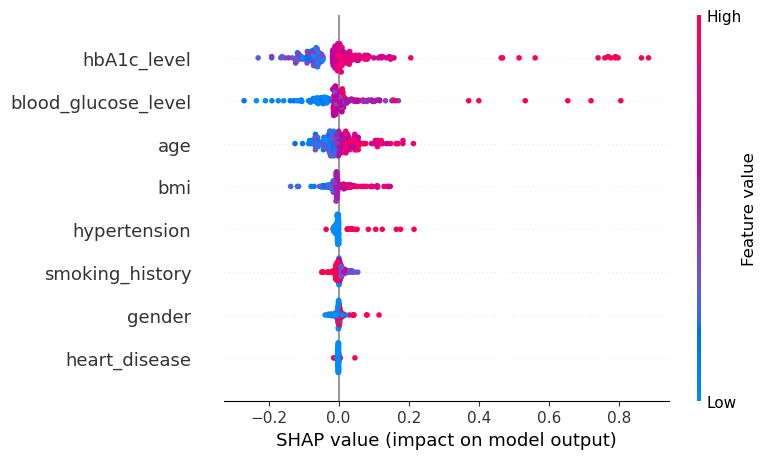

In [63]:
# If SHAP returns a 3D array (samples, features, classes)
if len(np.array(shap_values).shape) == 3:
    shap_diabetes = shap_values[:, :, 1]   # Class 1 = diabetic

# If SHAP returns a list (older SHAP versions)
elif isinstance(shap_values, list):
    shap_diabetes = shap_values[1]

# Already a 2D array
else:
    shap_diabetes = shap_values

# Summary plot
shap.summary_plot(
    shap_diabetes,
    X_sample,
    feature_names=X.columns.tolist()
)

In [71]:
import numpy as np

# Predict probabilities from the stacked TaReDNet model
stack_probs = stack_dnn.predict(X_meta_test, verbose=0).ravel()

# Convert probabilities to binary class labels
y_pred = (stack_probs >= 0.5).astype(int)

print("stack_probs shape:", stack_probs.shape)
print("y_pred shape:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])

stack_probs shape: (15000,)
y_pred shape: (15000,)
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


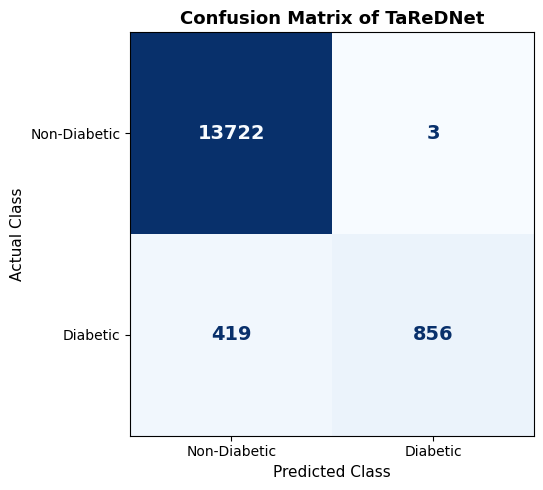

In [79]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5.5, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False,
    values_format="d"
)

# Improve formatting for IEEE paper
ax.set_title("Confusion Matrix of TaReDNet", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Class", fontsize=11)
ax.set_ylabel("Actual Class", fontsize=11)

# Increase font size of numbers inside the cells
for text in ax.texts:
    text.set_fontsize(14)
    text.set_fontweight("bold")

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "Figure_4_Confusion_Matrix_TaReDNet.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [80]:
# Save the entire TaReDNet model
stack_dnn.save("TaReDNet_Diabetes_Model.keras")

print("TaReDNet model saved successfully.")

TaReDNet model saved successfully.
